# 🟠 Tarefa 6

* Disciplina: Física com Python 1 (2026.2) — CBPF
* Autor: Luiz Guilherme Ataliba dos Reis
* Obs: Código desenvolvido para fins de avaliação acadêmica. Disponibilizado publicamente sob a Licença MIT para consulta educacional.

> **Entrega:** colocar no GitHub.

In [ ]:
import time

import numba
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme("notebook")
sns.set_style("darkgrid")


In [ ]:
# Definições

def varredura_metropolis(spins, beta, J, L, N, passos_termico, passos_medida, semente):
    """O laço de Metropolis: N sorteios de sítio por varredura. Fica como função, e não como método,
    porque o numba compila funções.

    Parâmetros
    ----------
    spins: Rede de spins atualizada inplace, tamanho N.
    J: Acoplamento entre spins vizinhos, o artigo usa J = 1.
    L: Lado da rede LxL; L = 2 é a rede com solução exata fechada.
    N: Número de spins da rede, N = L².
    passos_termico: Passos transiente.
    passos_medida: Varreduras medidas.

    Retorna
    ---------
    tuple(<E>, <E^2>, <M>, <M^2>)
    """

    np.random.seed(semente)
    soma_e = soma_e2 = soma_m = soma_m2 = 0.0

    for passo in range(passos_termico + passos_medida):

        # 1 Passo de monte carlo, varremos N spins em 1 passo.
        for _ in range(N):
            i = np.random.randint(0, N)     # sítio sorteado
            r = np.random.random()          
            linha, coluna = i // L, i % L

            # Soma do spin dos vizinhos
            vizinhos = (spins[linha * L + (coluna + 1) % L] + spins[linha * L + (coluna - 1) % L]
                        + spins[((linha + 1) % L) * L + coluna] + spins[((linha - 1) % L) * L + coluna])

            # Variação de energia
            dE = 2.0 * J * spins[i] * vizinhos            
            if dE <= 0.0 or r < np.exp(-beta * dE):
                spins[i] = -spins[i]                      

        # Medindo depois do transiente
        if passo >= passos_termico:                          
            # Energia e magnetização
            e = 0.0
            m = 0

            for i in range(N):
                linha, coluna = i // L, i % L
                e -= J * spins[i] * (spins[linha * L + (coluna + 1) % L]
                                     + spins[((linha + 1) % L) * L + coluna])
                m += spins[i]

            soma_e += e
            soma_e2 += e * e
            soma_m += abs(m)
            soma_m2 += m * m

    return soma_e / passos_medida, soma_e2 / passos_medida, soma_m / passos_medida, soma_m2 / passos_medida


varredura_compilada = numba.njit(varredura_metropolis)   # compilada uma vez, na primeira chamada


class SimulacaoDeIsing:
    """Modelo de Ising 2x2: Monte Carlo de Metropolis e a solução exata da tabela 1."""

    def __init__(self, L=2, J=1.0, semente=12345, temperaturas=None,
                passos_termico=2_000, passos_medida=10_000):
        self.L = L
        self.J = J
        self.N = L * L
        self.semente = semente
        self.temperaturas = temperaturas if temperaturas else np.linspace(0.5, 5.0, 40)
        self.passos_termico = passos_termico
        self.passos_medida = passos_medida
        self.spins = np.ones(self.N, dtype=np.int64)   # começa com todos os spins para cima
        self.varredura = varredura_metropolis

        # (energia, |magnetização|, degenerescência): as configurações A, B, C e D da figura 16
        self.CONFIGURACOES = [(-8.0, 4, 2), (0.0, 2, 8), (0.0, 0, 4), (8.0, 0, 2)]

    def energia(self):
        total = 0.0
        for i in range(self.N):
            linha, coluna = i // self.L, i % self.L
            direita = linha * self.L + (coluna + 1) % self.L
            abaixo = ((linha + 1) % self.L) * self.L + coluna
            total -= self.J * self.spins[i] * (self.spins[direita] + self.spins[abaixo])
        return total

    def magnetizacao(self):
        return int(self.spins.sum())

    def medir(self, temperatura):
        return self.varredura(self.spins, self.J / temperatura, self.J, self.L, self.N,
                              self.passos_termico, self.passos_medida, self.semente)

    def simular(self, compilada=False):
        # varre a grade de temperaturas; cada temperatura começa da rede alinhada
        self.varredura = varredura_compilada if compilada else varredura_metropolis
        dados = []
        for T in self.temperaturas:
            self.spins[:] = 1
            dados.append(self.medir(T))
        return np.array(dados)

    def observaveis(self, dados):
        C = (dados[:, 1] - dados[:, 0] ** 2) / (self.N * self.temperaturas ** 2)
        chi = (dados[:, 3] - dados[:, 2] ** 2) / (self.N * self.temperaturas)
        return C, chi

    def exatas(self):
        """ Soma sobre as quatro configurações da tabela 1"""
        C, chi = [], []
        for T in self.temperaturas:
            beta = self.J / T
            pesos = np.array([g * np.exp(-beta * E) for E, _, g in self.CONFIGURACOES])
            Z = pesos.sum()
            e1 = sum(p * E for p, (E, _, _) in zip(pesos, self.CONFIGURACOES)) / Z
            e2 = sum(p * E * E for p, (E, _, _) in zip(pesos, self.CONFIGURACOES)) / Z
            m1 = sum(p * M for p, (_, M, _) in zip(pesos, self.CONFIGURACOES)) / Z
            m2 = sum(p * M * M for p, (_, M, _) in zip(pesos, self.CONFIGURACOES)) / Z
            C.append((e2 - e1 * e1) / (self.N * T * T))
            chi.append((m2 - m1 * m1) / (self.N * T))
        return np.array(C), np.array(chi)

    def executar(self):
        """ Roda as duas versões, imprime a comparação e devolve as curvas para o gráfico"""
        self.spins[:] = 1                  # conferência da convenção de energia: E = −8 e |M| = 4
        print(f"rede alinhada: E = {self.energia():+.0f}, M = {self.magnetizacao():+d}")

        # Simulação sem numba
        t0 = time.perf_counter()
        dados_python = self.simular(compilada=False)
        tempo_python = time.perf_counter() - t0

        # Simulação com numba
        self.simular(compilada=True)       # aquece a compilação do numba, resultado descartado
        t0 = time.perf_counter()
        dados_numba = self.simular(compilada=True)
        tempo_numba = time.perf_counter() - t0

        C_python, _ = self.observaveis(dados_python)
        C_numba, chi_numba = self.observaveis(dados_numba)
        C_exato, chi_exato = self.exatas()

        print(f"Python puro: {tempo_python:7.2f} s")
        print(f"numba:       {tempo_numba:7.2f} s")
        print(f"aceleração:  {tempo_python / tempo_numba:7.0f}x")
        # as duas versões sorteiam a mesma sequência, então devem concordar exatamente
        print(f"maior diferença com/sem numba em C/N: {np.max(np.abs(C_numba - C_python)):.2e}")
        print(f"maior desvio de C/N:   {np.max(np.abs(C_numba - C_exato)):.4f}")
        print(f"maior desvio de χ'/N:  {np.max(np.abs(chi_numba - chi_exato)):.4f}")

        return C_numba, chi_numba, C_exato, chi_exato


In [9]:
# Simulação

simulacao = SimulacaoDeIsing()

C_numba, chi_numba, C_exato, chi_exato = simulacao.executar()


rede alinhada: E = -8, M = +4
Python puro:   19.07 s
numba:          0.21 s
aceleração:       91
maior diferença com/sem numba em C/N: 0.00e+00
maior desvio de C/N:   0.0162
maior desvio de χ'/N:  0.0034


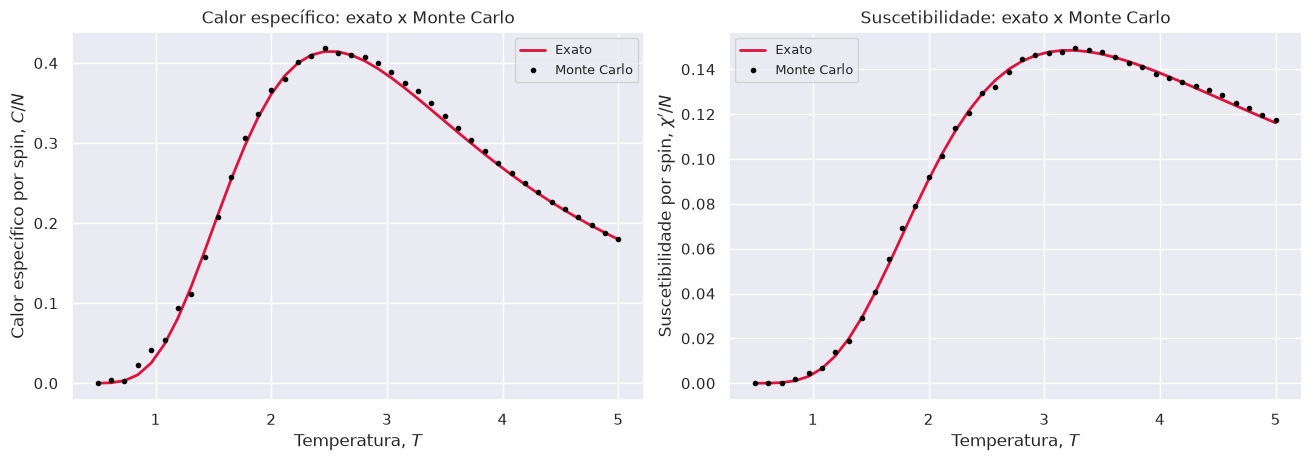

In [13]:
# Plotting

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

axs[0].plot(simulacao.temperaturas, C_exato, color="crimson", lw=2, label="Exato")
axs[0].plot(simulacao.temperaturas, C_numba, "o", ms=3, color="black", label="Monte Carlo")
axs[0].set(xlabel="Temperatura, $T$", ylabel="Calor específico por spin, $C/N$",
           title="Calor específico: exato x Monte Carlo")

axs[1].plot(simulacao.temperaturas, chi_exato, color="crimson", lw=2, label="Exato")
axs[1].plot(simulacao.temperaturas, chi_numba, "o", ms=3, color="black", label="Monte Carlo")
axs[1].set(xlabel="Temperatura, $T$", ylabel=r"Suscetibilidade por spin, $\chi'/N$",
           title="Suscetibilidade: exato x Monte Carlo")

axs[0].legend(fontsize=9)
axs[1].legend(fontsize=9)
